LangChain is an open-source framework for developing applications powered by LLMs. It provides components to connect language models with prompts, 
documents, retrievers, tools, APIs, and memory-like conversation state.

Typical applications:
- RAG-based question-answering systems.
- Document analysis.
- AI assistants.
- Tool-calling agents.
- Multi-step reasoning workflows.

#### What are the main components of LangChain?

| Component | Purpose |
| :--- | :--- |
| Models | Connect to LLMs |
| Prompts | Structure instructions and input |
| Output Parsers | Format model responses |
| Documents | Store text and metadata |
| Document Loaders | Load external content |
| Text Splitters | Divide documents into chunks |
| Embeddings | Convert text into vectors |
| Vector Stores | Store and search vectors |
| Retrievers | Retrieve relevant documents |
| Tools | Allow LLMs to execute external functions |
| Agents | Decide which tool to use |

#### What is the difference between LLM and ChatModel?
- LLM interfaces traditionally **accept text and return text**.
- ChatModel interfaces **accept messages with roles** such as system, human, and assistant, and return AI messages.

#### What are the stages of a RAG pipeline?
1. Document ingestion.
2. Text extraction.
3. Document cleaning.
4. Text chunking.
5. Embedding generation.
6. Vector database indexing.
7. Query embedding.
8. Similarity search.
9. Context retrieval.
10. LLM response generation.

#### What is a Document Loader?
A component that loads data from different sources into LangChain Document objects.
Examples:
- PDF files.
- Text files.
- Webpages.
- CSV files.
- Databases.

#### What is Chunk Overlap in RAG? Explain  Text chunking.

In a Retrieval-Augmented Generation (RAG) pipeline, a large document is split into smaller chunks before creating embeddings and storing them in a vector database. Chunk overlap means that some text from the end of one chunk is repeated at the beginning of the next chunk.

#### Example: Without Overlap

Suppose we have this text: "Transformers use self-attention mechanisms to capture relationships between words. Self-attention computes attention scores between tokens. These scores help the model identify important contextual information."

Chunk Size = 10 words Overlap = 0 [No Overlap]

- Chunk 1: Transformers use self-attention mechanisms to capture relationships between words.
- Chunk 2: Self-attention computes attention scores between tokens.
- Chunk 3: These scores help the model identify important contextual information.

### Problem:
- If user asks:
    > "How does self-attention compute attention scores?"
- The important context may be split across Chunk 1 and Chunk 2. Retriever might fetch only Chunk 2 and lose the definition from Chunk 1.

#### With Overlap
- Chunk Size = 10 words Overlap = 3 words
    - Chunk 1: Transformers use self-attention mechanisms to capture relationships between words.
    - Chunk 2: relationships between words. Self-attention computes attention scores between tokens.
    - Chunk 3: scores between tokens. These scores help the model identify important contextual information.
Notice:
- Chunk 1 ends with: relationships between words
- Chunk 2 starts with: relationships between words
Those 3 words are repeated. This preserves context across chunk boundaries.

## Embedding Models vs Transformer models

#### What is difference between Embedding Models and Transformer models?

Embedding Models convert text into numerical vectors. Transformer Models are the neural network architecture that powers models like BERT, GPT, Llama, DistilBERT, etc.

#### Transformer Model
```
Input
 ↓
Tokenizer
 ↓
Embeddings
 ↓
Multi-Head Attention
 ↓
Feed Forward Network
 ↓
Output
```
```
BERT
GPT
DistilBERT
RoBERTa
T5
Llama
Gemma
Mistral
```

#### Embedding Model

An embedding model is trained specifically to produce meaningful vector representations. The vector captures semantic meaning. These vectors are stored in a Vector Database.
```
all-MiniLM-L6-v2
BGE-small
BGE-base
E5-large
text-embedding-3-small
text-embedding-3-large
```
#### Where Embeddings Are Used ?
```
RAG
Semantic Search
Recommendation Systems
Document Similarity
Clustering
Retrieval
```
| Feature | Embedding Model | LLM |
| :--- | :--- | :--- |
| Purpose | Create vectors | Generate text |
| Output | Numerical vector | Natural language |
| Used in | Retrieval/Search | Answer generation |
| Stored in VDB | Yes | No |
| RAG Stage | Retrieval | Generation |


## Embedding Models vs VDB models
#### Embedding Models and VDB models both are same?

No, Embedding Model and Vector Database (VDB) are completely different components in a RAG system.
- Embedding Model = Creates vectors
- Vector Database = Stores vectors

#### Example:

Embedding Model Input ["What is AI?"] , Output [0.23, -0.11, 0.87, 0.45, ...]

Now Vector Database Models do: [0.23, -0.11, 0.87, ...] VDB models performed
- Store it
- Search it
- Retrieve nearest vectors
- Task
    - Store Vectors + Similarity Search

## VDB Models
```
FAISS
ChromaDB
Pinecone
Qdrant
Milvus
Azure AI Search
```

## LangChain Flow

```
                    LangChain
                         │
 ┌───────────────────────┼───────────────────────┐
 │                       │                       │
 ▼                       ▼                       ▼

User Query → Retriever → Vector DB → Context Builder → LLM → Answer

               (all coordinated by LangChain)
```

## Complete RAG Flow

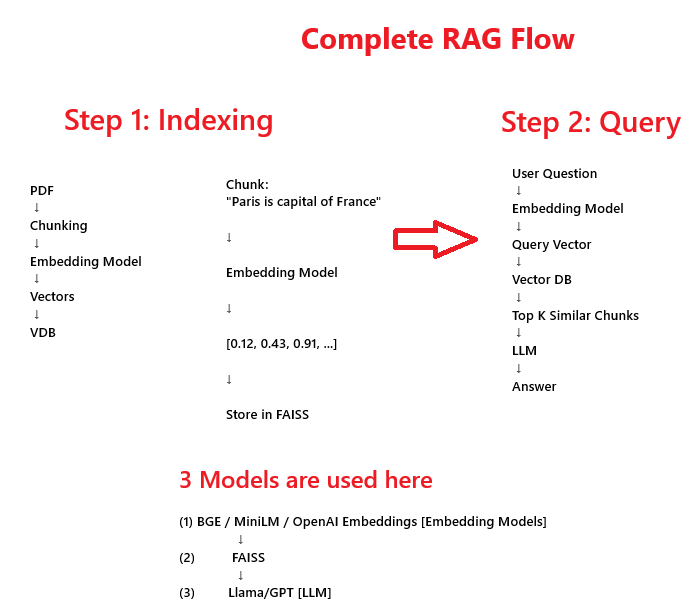


## Retriever in LangChain
A Retriever in LangChain is a component responsible for finding and returning relevant documents based on a user's question.

**Retriever = Information Search + Relevant Document Selection.**

The primary task of a Retriever in a vector-based RAG application is:
1. Similarity Search: Find documents whose embeddings are semantically similar to the user's query embedding.
2. Top-K Retrieval: Return the K most relevant document chunks based on the selected retrieval strategy.

#### Retriever workflow

```
[ User Query ]
"Explain Wi-Fi Beamforming"
       ↓
[ Embedding Model ]
Converts query into a vector representation
       ↓
[ Retriever ]
Searches for relevant information
       ↓
[ Vector Database Results ]
Document 1 - Beamforming basics     [Relevant]
Document 2 - MU-MIMO                [Relevant]
Document 3 - Channel utilization    [Less relevant]
       ↓
[ LLM (Qwen / Llama) ]
Generates an answer using retrieved context
```


## FAISS is the VDB models. So similarity finding & Top K chunk performed by FASSI? I just want to know what API use by Retrievers.

Yes, **FAISS is a vector search library**, `not an embedding model`. It performs vector similarity search and can return the Top-K matching vectors.

| Component | Responsibility |
| :--- | :--- |
| Embedding Model | Converts query into a vector |
| FAISS | Performs vector similarity search and returns Top-K matches |
| LangChain Retriever | Provides the retrieval interface and invokes the underlying search |
| LLM | Generates the final answer |

## Steps

#### 1. Create FAISS vector database:
```python
from langchain_community.vectorstores import FAISS

vectorstore = FAISS.from_documents(
    documents=chunks,
    embedding=embedding_model
)
```
#### 2. Create Retriever
```python
retriever = vectorstore.as_retriever(
    search_type="similarity",
    search_kwargs={"k": 5}
)
```
#### 3. Retrieve documents
```python
results = retriever.invoke(
    "Explain Wi-Fi Beamforming"
)
```
#### execution flow
```text
      retriever.invoke(query)
                 ↓
    LangChain VectorStoreRetriever
                 ↓
 vectorstore.similarity_search(query, k=5)
                 ↓
       FAISS similarity search
  Query embedding + indexed vectors
                 ↓
  Top-5 matching documents returned
```

### Important APIs to remember

| API | Purpose |
| :--- | :--- |
| `vectorstore.as_retriever()` | Creates Retriever |
| `retriever.invoke(query)` | Retrieves documents |
| `vectorstore.similarity_search()` | Similarity-based retrieval |
| `vectorstore.similarity_search_with_score()` | Retrieves documents with scores/distances |
| `vectorstore.max_marginal_relevance_search()` | Retrieves diverse relevant documents |
| `vectorstore.similarity_search_by_vector()` | Searches using an existing query vector |

## So when I used FASSI we do not required other VDB models? Can we usei use FASSI only for similarity search and Top K chunk with VDB models such as ChromaDB or Qdrant?

You can use FAISS alone, or use ChromaDB / Qdrant instead of FAISS. Do not need to combine them. FAISS can perform vector similarity search and Top-K retrieval without another vector database.

##### Can we combine FAISS with ChromaDB or Qdrant?
Technically, yes, but normally there is no need.

| Architecture | Possible? | Recommendation |
| :--- | :--- | :--- |
| FAISS alone | Yes | Good for local vector search |
| ChromaDB alone | Yes | Good for local RAG applications |
| Qdrant alone | Yes | Good for scalable RAG applications |
| FAISS + ChromaDB | Yes, with custom integration | `Usually unnecessary` |
| FAISS + Qdrant | Yes, with custom integration | `Usually unnecessary` |

### Option A: FAISS
```text
Embedding Model
       ↓
  FAISS Index
       ↓
Top-K Documents
```
### Option B: Qdrant
```text
     Embedding Model
            ↓
 Qdrant Vector Database
            ↓
     Top-K Documents
```
### Option C: ChromaDB
```text
     Embedding Model
            ↓
ChromaDB Vector Database
            ↓
     Top-K Documents
```


## what is scalable RAG applications
A Scalable RAG Application is a RAG system that can efficiently handle:
- Millions of documents
- Thousands/millions of users
- Large query volumes
- Continuous document updates
- Low response latency
without significant performance degradation.

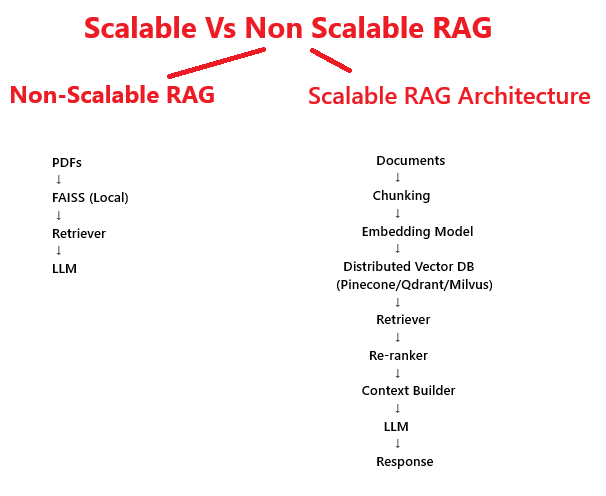


#### Code implementations Architecture

```text
       albert-einstein-digital.pdf
         Current working directory
                     ↓
         LangChain PyPDFLoader
        PDF pages → Documents
                     ↓
  RecursiveCharacterTextSplitter
    Chunk size: 1000, overlap: 200
                     ↓
   Hugging Face Embedding Model
        PyTorch + NVIDIA CUDA
                     ↓
     ┌───────────────┼───────────────┐
     ↓               ↓               ↓
   FAISS          Qdrant         ChromaDB
Vector store   Vector store    Vector store
```

In [1]:
from pathlib import Path
import shutil
import warnings

import torch

from qdrant_client import QdrantClient

from langchain_community.document_loaders import PyPDFLoader
from langchain_community.vectorstores import FAISS

from langchain_text_splitters import RecursiveCharacterTextSplitter

from langchain_huggingface import HuggingFaceEmbeddings

from langchain_qdrant import QdrantVectorStore
from qdrant_client import QdrantClient
from langchain_chroma import Chroma

# Suppress deprecation warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

/tmp/ipykernel_15674/1883841952.py:9: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader


In [2]:
# ---------------------------------------
# 1. Configuration
# ---------------------------------------
PDF_PATH = Path.cwd() / "albert-einstein-digital.pdf"

BASE_DIR = Path.cwd() / "vector_stores"
FAISS_DIR = BASE_DIR / "faiss"
QDRANT_DIR = BASE_DIR / "qdrant"
CHROMA_DIR = BASE_DIR / "chroma"

COLLECTION_NAME = "einstein_documents"

CHUNK_SIZE = 1000
CHUNK_OVERLAP = 200

In [3]:
# ---------------------------------------
# 2. Verify CUDA / PyTorch
# ---------------------------------------
print("\n========== GPU INFORMATION ==========")

print("PyTorch version:", torch.__version__)
print("CUDA runtime:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    DEVICE = "cuda"
    print("GPU:", torch.cuda.get_device_name(0))
else:
    DEVICE = "cpu"
    print("Using CPU fallback")


========== GPU INFORMATION ==========
PyTorch version: 2.14.1+cu130
CUDA runtime: 13.0
CUDA available: True
GPU: NVIDIA GB10


In [4]:
# ---------------------------------------
# 3. Load PDF
# ---------------------------------------
print("\n========== LOADING PDF ==========")

if not PDF_PATH.is_file():
    raise FileNotFoundError(
        f"PDF not found: {PDF_PATH}"
    )

loader = PyPDFLoader(str(PDF_PATH))
documents = loader.load()

print("Total PDF pages:", len(documents))


========== LOADING PDF ==========
Total PDF pages: 104


## Chunk Statistics

In [5]:
# ---------------------------------------
# 4. Split PDF into chunks
# ---------------------------------------
print("\n========== TEXT CHUNKING ==========")

splitter = RecursiveCharacterTextSplitter(
    chunk_size=CHUNK_SIZE,
    chunk_overlap=CHUNK_OVERLAP,
    separators=["\n\n", "\n", ". ", " ", ""]
)

chunks = splitter.split_documents(documents)

# Remove empty chunks
chunks = [
    doc for doc in chunks
    if doc.page_content.strip()
]

if not chunks:
    raise ValueError(
        "No text extracted from the PDF."
    )

# ---------------------------------------
# Chunk Statistics
# ---------------------------------------
print(f"\nTotal Chunks Created: {len(chunks)}")

chunk_lengths = [len(chunk.page_content) for chunk in chunks]

print(f"Min Chunk Size : {min(chunk_lengths)} characters")
print(f"Max Chunk Size : {max(chunk_lengths)} characters")
print(f"Avg Chunk Size : {sum(chunk_lengths)/len(chunk_lengths):.2f} characters")

# ---------------------------------------
# Show First 2 Chunks
# ---------------------------------------
for i, chunk in enumerate(chunks[:3]):
    print("\n" + "="*80)
    print(f"Chunk #{i+1}")
    print("="*80)

    print(f"Length : {len(chunk.page_content)} chars")

    print("\nContent Preview:")
    print(chunk.page_content[:500])

    print("\nMetadata:")
    print(chunk.metadata)


========== TEXT CHUNKING ==========

Total Chunks Created: 254
Min Chunk Size : 35 characters
Max Chunk Size : 1000 characters
Avg Chunk Size : 776.05 characters

Chunk #1
Length : 68 chars

Content Preview:
rebel lives albert einstein  rebel lives albert einstein rebel lives

Metadata:
{'producer': 'Acrobat Distiller 5.0.5 (Windows)', 'creator': 'PageMaker 6.5', 'creationdate': '2003-04-16T05:42:00+00:00', 'author': 'alex', 'moddate': '2024-06-14T10:45:27-04:00', 'title': 'einstein prelims.p65', 'source': '/home/todo_gx10/mlx/nlp-foundations-to-llms/LlmEngineering/LangChain/albert-einstein-digital.pdf', 'total_pages': 104, 'page': 1, 'page_label': '2'}

Chunk #2
Length : 971 chars

Content Preview:
also published in the rebel lives  series:
Helen Keller, edited by John Davis
Haydée Santamaría, edited by Betsy Maclean
forthcoming in the rebel lives  series:
Sacco & Vanzetti, edited by John Davis
Louise Michel, edited by Nic Maclellan
Tamara “Tania” Bunke, by Ulises Estrada
rebel lives

In [6]:
# ---------------------------------------
# Visualize Overlap
# ---------------------------------------
for i in range(min(3, len(chunks))):
    print(f"\nChunk {i+1}")
    print("-"*80)

    text = chunks[i].page_content

    print("FIRST 100 CHARS:")
    print(text[:100])

    print("\nLAST 100 CHARS:")
    print(text[-100:])


Chunk 1
--------------------------------------------------------------------------------
FIRST 100 CHARS:
rebel lives albert einstein  rebel lives albert einstein rebel lives

LAST 100 CHARS:
rebel lives albert einstein  rebel lives albert einstein rebel lives

Chunk 2
--------------------------------------------------------------------------------
FIRST 100 CHARS:
also published in the rebel lives  series:
Helen Keller, edited by John Davis
Haydée Santamaría, edi

LAST 100 CHARS:
stories of  imperfect
revolutionary human beings to a new generation of  readers and aspiring rebels

Chunk 3
--------------------------------------------------------------------------------
FIRST 100 CHARS:
albert einstein
edited by Jim Green

LAST 100 CHARS:
albert einstein
edited by Jim Green


In [7]:
# ---------------------------------------
# Show Chunk Shape Before Embedding
# ---------------------------------------
for i, chunk in enumerate(chunks[:3]):
    print(f"""
Chunk {i+1}
-----------------------------------
Characters : {len(chunk.page_content)}
Words      : {len(chunk.page_content.split())}
""")


Chunk 1
-----------------------------------
Characters : 68
Words      : 10


Chunk 2
-----------------------------------
Characters : 971
Words      : 150


Chunk 3
-----------------------------------
Characters : 35
Words      : 6



## Token-Based Chunks

In [8]:
# ---------------------------------------
# Token-Based Chunks
# ---------------------------------------

from langchain_text_splitters import TokenTextSplitter

token_based_splitter = TokenTextSplitter(
    chunk_size=512,
    chunk_overlap=50
)

token_based_chunks = token_based_splitter.split_documents(documents)

In [9]:
# ---------------------------------------
# debugging a RAG pipeline
# ---------------------------------------
print("No. of documents:", len(documents))
print("No. of chunks:", len(chunks))
print("Chunk size:", CHUNK_SIZE)
print("Chunk overlap:", CHUNK_OVERLAP)

No. of documents: 104
No. of chunks: 254
Chunk size: 1000
Chunk overlap: 200


In [10]:
# ---------------------------------------
# 5. Load embedding model on GPU
# ---------------------------------------
print("\n========== EMBEDDING MODEL [sentence-transformers/all-MiniLM-L6-v2]==========")
MODEL_NAME = (
    "sentence-transformers/all-MiniLM-L6-v2"
)

embeddings = HuggingFaceEmbeddings(
    model_name=MODEL_NAME,
    model_kwargs={
        "device": DEVICE
    },
    encode_kwargs={
        "batch_size": 32,
        "normalize_embeddings": True
    }
)
# Verify embedding dimension
sample_vector = embeddings.embed_query(
    "Albert Einstein theory of relativity"
)

print("Embedding dimension:", len(sample_vector))
print("Embedding device:", DEVICE)




========== EMBEDDING MODEL [sentence-transformers/all-MiniLM-L6-v2]==========


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Embedding dimension: 384
Embedding device: cuda


In [11]:
# ---------------------------------------
# 6. Prepare storage
# ---------------------------------------
BASE_DIR.mkdir(parents=True, exist_ok=True)

# Rebuild databases from scratch.
# Warning: existing indexes will be deleted.
for directory in [FAISS_DIR, QDRANT_DIR, CHROMA_DIR]:
    if directory.exists():
        shutil.rmtree(directory)

In [12]:
# ---------------------------------------
# 7. Create FAISS vector store
# ---------------------------------------
print("\n========== CREATING FAISS ==========")

faiss_db = FAISS.from_documents(
    documents=chunks,
    embedding=embeddings
)

faiss_db.save_local(str(FAISS_DIR))

print("FAISS saved:", FAISS_DIR)


========== CREATING FAISS ==========
FAISS saved: /home/todo_gx10/mlx/nlp-foundations-to-llms/LlmEngineering/LangChain/vector_stores/faiss


In [13]:
# ---------------------------------------
# 8. Create Qdrant vector store
# ---------------------------------------
print("\n========== CREATING QDRANT ==========")

QDRANT_DIR = str(BASE_DIR / "qdrant")

qdrant_db = QdrantVectorStore.from_documents(
    documents=chunks,
    embedding=embeddings,
    path=QDRANT_DIR,
    collection_name="einstein_documents",
    force_recreate=True
)

print("Qdrant database created successfully!")


========== CREATING QDRANT ==========
Qdrant database created successfully!


In [14]:
# ---------------------------------------
# 9. Create ChromaDB vector store
# ---------------------------------------
print("\n========== CREATING CHROMADB ==========")

chroma_db = Chroma.from_documents(
    documents=chunks,
    embedding=embeddings,
    collection_name=COLLECTION_NAME,
    persist_directory=str(CHROMA_DIR)
)

print("ChromaDB saved:", CHROMA_DIR)


========== CREATING CHROMADB ==========
ChromaDB saved: /home/todo_gx10/mlx/nlp-foundations-to-llms/LlmEngineering/LangChain/vector_stores/chroma


In [15]:
# ---------------------------------------
# 10. Summary
# ---------------------------------------
print("\n========== COMPLETED ==========")
print("PDF pages:", len(documents))
print("Document chunks:", len(chunks))
print("Embedding dimension:", len(sample_vector))
print("Embedding device:", DEVICE)

print("\nCreated:")
print("1. FAISS")
print("2. Qdrant")
print("3. ChromaDB")


========== COMPLETED ==========
PDF pages: 104
Document chunks: 254
Embedding dimension: 384
Embedding device: cuda

Created:
1. FAISS
2. Qdrant
3. ChromaDB


## Vector storage Directory

```tesxt
├── chroma
│   ├── chroma.sqlite3
│   └── d4c831e0-5405-4442-a3ae-b7dc9bc0e3f3
│       ├── data_level0.bin
│       ├── header.bin
│       ├── length.bin
│       └── link_lists.bin
├── faiss
│   ├── index.faiss [This is the actual vector database. It contains Embedding vectors FAISS search index, 
|   |                Vector structures, Nearest-neighbor search data]      
│   └── index.pkl   This is a Python Pickle file. It contains metadata needed by LangChain. Typically
|                    docstore, index_to_docstore_id, metadata
└── qdrant
    ├── collection
    │   └── einstein_documents
    │       └── storage.sqlite
    └── meta.json
```

## Query the vector databases using LangChain Retriever

In [16]:
MODEL_NAME = (
    "sentence-transformers/all-MiniLM-L6-v2"
)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Same embedding model used during indexing
embeddings = HuggingFaceEmbeddings(
    model_name=MODEL_NAME,
    model_kwargs={"device": DEVICE},
    encode_kwargs={
        "batch_size": 32,
        "normalize_embeddings": True
    }
)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [17]:
# ---------------------------------------
# Load FAISS
# ---------------------------------------
faiss_db = FAISS.load_local(
    str(BASE_DIR / "faiss"),
    embeddings,
    allow_dangerous_deserialization=True
)

# ---------------------------------------
# Load Qdrant
# ---------------------------------------

print("Qdrant database loaded successfully!")
print("Qdrant collection recreated successfully!")
# ---------------------------------------
# Load ChromaDB
# ---------------------------------------
chroma_db = Chroma(
    collection_name=COLLECTION_NAME,
    embedding_function=embeddings,
    persist_directory=str(BASE_DIR / "chroma")
)


Qdrant database loaded successfully!
Qdrant collection recreated successfully!


In [18]:
# ---------------------------------------
# Create retrievers
# ---------------------------------------
retrievers = {
    "FAISS": faiss_db.as_retriever(
        search_kwargs={"k": 3}
    ),
    #"Qdrant": qdrant_db.as_retriever(
    #    search_kwargs={"k": 3}
    #),
    "ChromaDB": chroma_db.as_retriever(
        search_kwargs={"k": 3}
    )
}

In [19]:
# Check FAISS dimensions
print("FAISS index dimension:", faiss_db.index.d)

# Check current embedding dimensions
query_vector = embeddings.embed_query(
    "What is Albert Einstein's theory of relativity?"
)

print("Query embedding dimension:", len(query_vector))

FAISS index dimension: 384
Query embedding dimension: 384


In [20]:
# ---------------------------------------
# Search
# ---------------------------------------
query = "What is Albert Einstein's theory of relativity?"

for name, retriever in retrievers.items():

    print(f"\n========== {name} ==========")

    results = retriever.invoke(query)

    for index, doc in enumerate(results, start=1):

        print(f"\nTop-{index}")
        print("Page:", doc.metadata.get("page"))
        print("Source:", doc.metadata.get("source"))
        print("Content:", doc.page_content[:500])




========== FAISS ==========

Top-1
Page: 11
Source: /home/todo_gx10/mlx/nlp-foundations-to-llms/LlmEngineering/LangChain/albert-einstein-digital.pdf
Content: cized and more generally his attitudes toward women were far
less progressive than might have been expected from someone
with such a radical take on other issues.
Yet Einstein’s major preoccupation during and after World
War I — of far greater importance to him than either his family or
political work — was his scientific research. During the war, Ein-
stein extended his work on relativity to complete a general theory
of relativity, fundamentally reconceptualizing the relations between

Top-2
Page: 3
Source: /home/todo_gx10/mlx/nlp-foundations-to-llms/LlmEngineering/LangChain/albert-einstein-digital.pdf
Content: albert einstein
edited by Jim Green

Top-3
Page: 10
Source: /home/todo_gx10/mlx/nlp-foundations-to-llms/LlmEngineering/LangChain/albert-einstein-digital.pdf
Content: introduction     3
In 1903, Einstein married Mileva Mar